# 06 · Embedding MLP (Step 3)

The brief's required deep-learning model: a compact MLP with **learned embeddings for airline, origin and destination**, on the same 40 numeric Phase 1 features, rows, splits and rolling folds as LogReg and XGBoost.

* **Network:** embeddings (width 1.6·n^0.56, at most 16) + numerics → 2–3 × [Linear → LayerNorm → ReLU → Dropout] → logit. LayerNorm, not BatchNorm, so a row's score never depends on the rest of its batch.
* **Loss:** binary cross-entropy, no class weights (calibrated probabilities are a deliverable).
* **Regularisation:** dropout, AdamW weight decay, early stopping on the **last 14 days of each fold's training window** (never the validation month).
* **Protocol:** 20 random configurations scored with one seed; the best is re-scored as a 5-seed ensemble (mean logit), which is the number used for model selection.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().resolve().parent
for p in (ROOT / 'src', ROOT.parent / 'phase1' / 'src'):
    sys.path.insert(0, str(p))

import aerocast_dl  # torch before XGBoost (OpenMP)
import numpy as np, pandas as pd
from IPython.display import Image, display
from aerocast_dl import config, pipeline
R, F = config.RESULTS_DIR, config.FIGURES_DIR
pd.set_option('display.precision', 4)


## 1. Search (single seed, rolling CV)

In [2]:
search = pd.read_csv(R / 'search_mlp.csv').sort_values('cv_pr_auc', ascending=False)
best = pipeline.load_spec('mlp')
assert all(getattr(best, k) == search.iloc[0][k] for k in config.MLP_GRID)
search.head(8)

,config,hidden,depth,dropout,emb_dropout,lr,weight_decay,cv_pr_auc,fold_m5,fold_m6,fold_m7,fold_m8,mean_best_epoch
5,5,128,2,0.3,0.0,0.001,1.0000e-04,0.4644,0.4280,0.5012,0.5495,0.3789,1.25
16,16,256,3,0.2,0.1,0.001,1.0000e-03,0.4582,0.4224,0.4887,0.5466,0.3749,1.25
7,7,128,3,0.1,0.0,0.001,1.0000e-04,0.4581,0.4214,0.4911,0.5539,0.3661,1.25
1,1,64,2,0.2,0.1,0.001,1.0000e-04,0.4577,0.4206,0.4935,0.5502,0.3666,2.25
6,6,128,3,0.1,0.0,0.001,1.0000e-05,0.4576,0.4215,0.4907,0.5526,0.3655,1.25
2,2,64,2,0.3,0.0,0.003,1.0000e-05,0.4575,0.4134,0.4931,0.5518,0.3717,1.25
4,4,128,2,0.2,0.0,0.003,1.0000e-05,0.4568,0.4174,0.4831,0.5483,0.3785,1.25
17,17,256,3,0.2,0.1,0.003,1.0000e-04,0.4557,0.4200,0.4789,0.5479,0.3761,1.00


## 2. Five-seed ensemble against Phase 1

Same four folds (validation May, Jun, Jul, Aug), each model scored as deployed. The paired fold differences matter more than the means: the fold-to-fold spread (~0.07) is much larger than the differences between models.

In [3]:
cv = pd.concat([pipeline.phase1_cv(), pd.read_csv(R / 'cv_models.csv')], ignore_index=True)
cv = cv[~cv['model'].str.startswith('ablation:')].set_index('model')
lr = cv.loc['Phase 1 LogReg', pipeline.FOLD_COLS].astype(float)
rows = ['Phase 1 LogReg', 'Phase 1 XGBoost', 'mlp']
t = cv.loc[rows, ['cv_pr_auc_mean', 'cv_pr_auc_std', *pipeline.FOLD_COLS, 'seed_sd_mean_over_folds', 'mean_best_epoch', 'n_params']]
d = cv.loc['mlp', pipeline.FOLD_COLS].astype(float) - lr
print(f'MLP - LogReg per fold: {np.round(d.to_numpy(), 4)} -> MLP better in {(d > 0).sum()}/4 folds')
t

MLP - LogReg per fold: [-0.0025 -0.0011 -0.0044 -0.0155] -> MLP better in 0/4 folds


,cv_pr_auc_mean,cv_pr_auc_std,fold_m5,fold_m6,fold_m7,fold_m8,seed_sd_mean_over_folds,mean_best_epoch,n_params
model,,,,,,,,,
Phase 1 LogReg,0.4714,0.0711,0.4343,0.5052,0.5525,0.3936,NaN,NaN,NaN
Phase 1 XGBoost,0.4500,0.0671,0.4315,0.4253,0.5479,0.3953,NaN,NaN,NaN
mlp,0.4655,0.0755,0.4317,0.5041,0.5481,0.3781,0.0035,1.95,27501.0


## 3. Learning curves

Largest fold (validation August), search seed, trained for every epoch without early stopping. The inner-holdout loss bottoms out after one or two epochs (the first 15 are shown) while the training loss keeps falling: early stopping, not the epoch budget, decides when the network stops.

Embedding MLP: best inner-holdout epoch 2, loss 0.5532 -> 0.5935 at epoch 15
MLP + GRU history: best inner-holdout epoch 2, loss 0.5513 -> 0.6665 at epoch 15


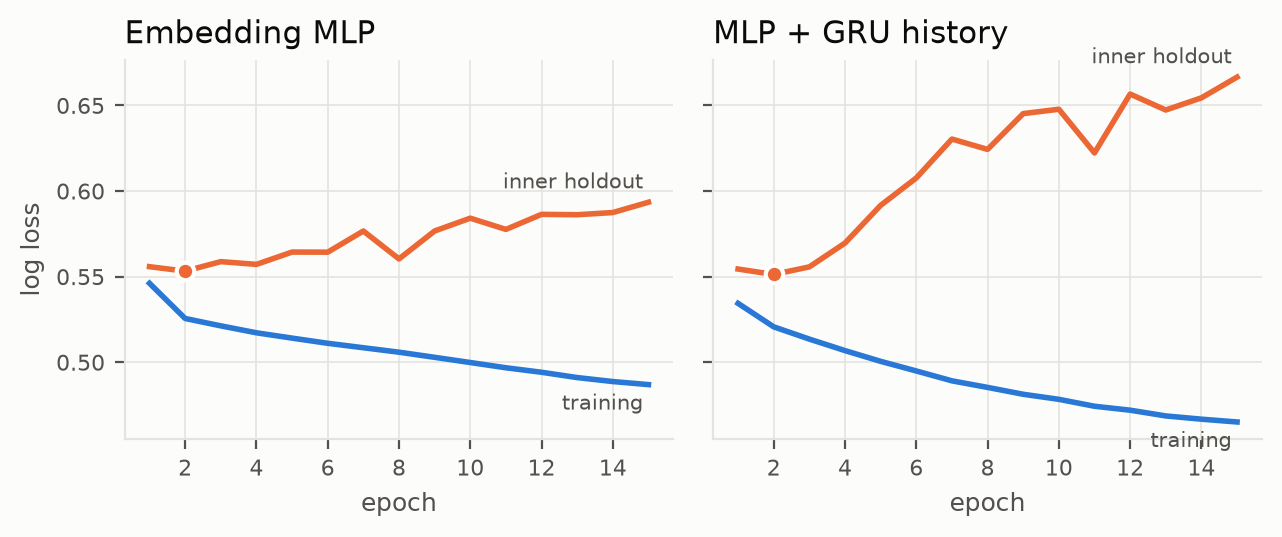

In [4]:
curves = json.loads((R / 'learning_curves.json').read_text())
for name, h in curves.items():
    es = [r['es_logloss'] for r in h]
    print(f"{name}: best inner-holdout epoch {int(np.argmin(es)) + 1}, loss {min(es):.4f} -> {es[-1]:.4f} at epoch {len(es)}")
display(Image(F / 'learning_curves.png', width=700))

## 4. What the embeddings learned

The final MLP's carrier and destination embeddings, projected on their first two principal components (seed 42). Neighbouring points are categories the network treats alike. This is descriptive only, not evidence for a causal grouping.

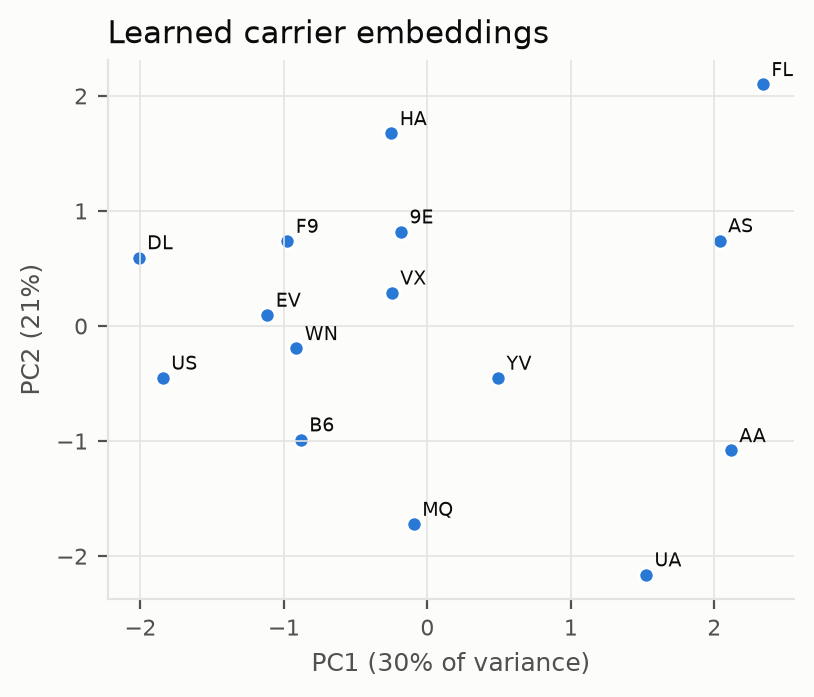

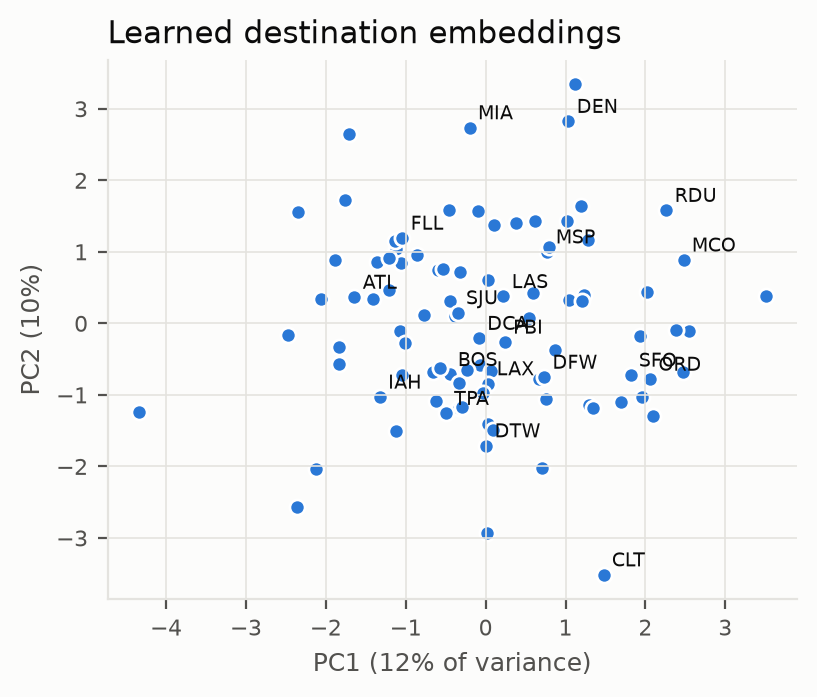

In [5]:
for f in ['embedding_carrier.png', 'embedding_dest.png']:
    if (F / f).exists():
        display(Image(F / f, width=420))
    else:
        print(f'{f}: produced by the final_fit stage')

## 5. Why does the MLP trail LogReg? (diagnostics, CV only)

Single seed, same folds, no calibration or test data. Each row changes one thing:

* **D0 → D1:** what LogReg loses without the fold's last 14 days, the rows an early-stopped network never trains on.
* **D2 → D3:** a network with one-hot inputs and **no hidden layer is a logistic regression**. If our training loop is sound, refitted it should land close to sklearn's LogReg (D0).
* **D3 → D5:** what the hidden layers add once both are trained the deployed way.
* **D6:** removing the day-level history (shared by 300–900 flights a day, the features a flexible model could use to memorise days).

The first run of this pipeline scored the early-stopped models (D2/D4-type) in CV; D1 vs D0 and D4 vs D5 showed that this scored a weaker procedure than the deployed refit, which led to the correction recorded in the protocol change log.

In [6]:
diag = pd.read_csv(R / 'diagnostics.csv').set_index('diagnostic')
d = diag['cv_pr_auc']
print(f"data lost by early stopping (LogReg D0-D1): {d['D0'] - d['D1']:+.4f}")
print(f"training loop vs sklearn (linear net D3 vs LogReg D0): {d['D3'] - d['D0']:+.4f}")
print(f"hidden layers once refitted (MLP D5 vs linear D3): {d['D5'] - d['D3']:+.4f}")
print(f"day-level history (D6 vs D5): {d['D6'] - d['D5']:+.4f}")
diag

data lost by early stopping (LogReg D0-D1): +0.0046
training loop vs sklearn (linear net D3 vs LogReg D0): -0.0075
hidden layers once refitted (MLP D5 vs linear D3): +0.0004
day-level history (D6 vs D5): -0.0129


,label,cv_pr_auc,fold_m5,fold_m6,fold_m7,fold_m8,best_epochs
diagnostic,,,,,,,
D0,"LogReg, all fold rows (Phase 1)",0.4714,0.4343,0.5052,0.5525,0.3936,///
D1,LogReg without the last 14 days,0.4668,0.4310,0.5026,0.5397,0.3939,///
D2,"linear network, early-stopped (no last 14 days)",0.4586,0.4070,0.5042,0.5294,0.3939,5/8/3/8
D3,"linear network, refitted on all fold rows",0.4640,0.4181,0.5024,0.5422,0.3931,5/8/3/8
D4,"selected MLP, early-stopped (no last 14 days)",0.4588,0.4215,0.4940,0.5331,0.3866,1/1/1/2
D5,"selected MLP, refitted on all fold rows",0.4644,0.4280,0.5012,0.5495,0.3789,1/1/1/2
D6,"selected MLP refitted, without day-level history",0.4515,0.3928,0.5074,0.5317,0.3739,1/1/3/1
